<a href="https://colab.research.google.com/github/Vidcito/RecuperacionDeInformacion-2026B/blob/main/Examen%20IB/examen1bim_DavidPuga.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Examen ICCD753 Recuperación de Información

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| NFCorpus | [BeIR/nfcorpus](https://huggingface.co/datasets/BeIR/nfcorpus) | [BeIR/nfcorpus-qrels](https://huggingface.co/datasets/BeIR/nfcorpus-qrels) |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Requisitos del sistema

### 3.1. Preparación e indexación

El sistema deberá:

1. Cargar e indexar los documentos del corpus asignado.
2. Aplicar y documentar las decisiones de preprocesamiento: tokenización, normalización, eliminación de stopwords y stemming o lematización.
3. Construir un vocabulario y un índice invertido que permita recuperar documentos.
4. Conservar la relación entre cada documento indexado y su identificador original.

La unidad de evaluación será el documento original, porque los qrels relacionan consultas con identificadores de documentos. No se debe dividir el texto en fragmentos.

### 3.2. Modelos de recuperación

Para cualquier consulta de texto, el sistema deberá producir dos rankings independientes:

- TF-IDF con similitud coseno.
- BM25.

Cada ranking deberá ordenar los documentos por puntuación de relevancia y permitir solicitar los primeros `k` resultados.

### 3.3. Servicio web

El sistema deberá estar publicado en internet y ofrecer, como mínimo, los siguientes endpoints:

**Comprobación de disponibilidad**

```http
GET /health
```

**Búsqueda**

```http
POST /search
Content-Type: application/json
```

Ejemplo de solicitud:

```json
{
  "query": "texto de la consulta",
  "model": "bm25",
  "top_k": 10
}
```

El campo `model` deberá aceptar `bm25` y `tfidf`. Una respuesta tendrá esta estructura:

```json
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "identificador_original",
      "score": 8.42,
      "title": "Título, si está disponible",
      "snippet": "Fragmento del documento recuperado"
    }
  ]
}
```

Los resultados deberán estar ordenados de mayor a menor puntuación, no contener documentos duplicados y respetar el valor solicitado de `top_k`. El servicio debe aceptar consultas que el estudiante no conozca de antemano.

## 4. Evaluación de la recuperación

Cada estudiante debe evaluar ambos modelos con consultas de la partición `test` y sus qrels. Presentará, como mínimo:

- Precision@10.
- Recall@10.
- NDCG@10.
- Una comparación de los resultados de TF-IDF y BM25.

En el Jupyter Notebook se deberá indicar qué consultas se utilizaron y permitir reproducir los cálculos. La evaluación del docente podrá utilizar otras consultas del mismo conjunto.

## 5. Prueba del docente

El docente accederá a la URL entregada y realizará solicitudes desde un cliente de web service para comprobar:

1. La disponibilidad del servicio.
2. El funcionamiento de TF-IDF y BM25.
3. El formato, orden y validez de los resultados.
4. La correspondencia de los `document_id` con el corpus y los qrels.
5. La respuesta ante consultas no incluidas en los ejemplos de entrega.

## 6. Entregables

Cada estudiante entregará:

1. La URL pública del servicio web, accesible durante el período de revisión.
2. El código en Jupyter Notebook con los resultados de la ejecución de cada bloque de código, incluyendo los resultados de las métricas de evaluación de los modelos de recuperación.

Se evaluará que ambos modelos funcionen correctamente y que cada estudiante interprete sus resultados.

# Solución examén
## David Alejandro Puga Novoa
### 18/11/2026


## 1. Corpus asignado

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |


In [2]:
CORPUS = "scifact"

In [3]:
%pip install -q "datasets<4" nltk scikit-learn numpy pandas matplotlib fastapi uvicorn httpx requests

Se instalaron las librerías base para el procesamiento lingüístico (nltk), cálculo matricial y disperso (numpy, scikit-learn), evaluación (pandas, matplotlib, scipy) y exposición REST (fastapi, uvicorn).

Se fija datasets<4 para mantener compatibilidad con los scripts de carga de los repositorios BeIR en Hugging Face.

## 2. Requisitos del sistema

### 2.1. Carga de datos

Se cargan documentos, consultas y qrels desde Hugging Face (`BeIR/<corpus>` y `BeIR/<corpus>-qrels`). Si Hugging Face falla, se usa como respaldo el mismo conjunto BEIR en su distribución original (zip). En ambos casos se conservan los identificadores originales (`_id` / `corpus-id`).

In [4]:
import io, json, zipfile, urllib.request
from collections import defaultdict

def load_from_hf(name):
    from datasets import load_dataset
    corpus = load_dataset(f"BeIR/{name}", "corpus")["corpus"]
    queries = load_dataset(f"BeIR/{name}", "queries")["queries"]
    qrels_ds = load_dataset(f"BeIR/{name}-qrels")
    docs = [{"_id": str(r["_id"]), "title": r["title"], "text": r["text"]} for r in corpus]
    qtext = {str(r["_id"]): r["text"] for r in queries}
    qrels = defaultdict(dict)
    for r in qrels_ds["test"]:
        qrels[str(r["query-id"])][str(r["corpus-id"])] = int(r["score"])
    return docs, qtext, dict(qrels)

def load_from_beir_zip(name):
    url = f"https://public.ukp.da.tu-darmstadt.de/thakur/BEIR/datasets/{name}.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    docs = [json.loads(l) for l in z.read(f"{name}/corpus.jsonl").decode().splitlines()]
    docs = [{"_id": str(d["_id"]), "title": d.get("title", ""), "text": d.get("text", "")} for d in docs]
    qtext = {str(q["_id"]): q["text"] for q in
             (json.loads(l) for l in z.read(f"{name}/queries.jsonl").decode().splitlines())}
    qrels = defaultdict(dict)
    for line in z.read(f"{name}/qrels/test.tsv").decode().splitlines()[1:]:
        q, d, s = line.split("\t")
        qrels[q][d] = int(s)
    return docs, qtext, dict(qrels)

try:
    docs, queries, qrels = load_from_hf(CORPUS)
    print("Cargado desde Hugging Face")
except Exception as e:
    print("Hugging Face falló (", type(e).__name__, "); usando zip de BEIR")
    docs, queries, qrels = load_from_beir_zip(CORPUS)

test_qids = [q for q in qrels if q in queries]   # consultas de la partición test con qrels
print(f"Documentos: {len(docs)} | consultas test con qrels: {len(test_qids)} | pares qrels test: {sum(len(v) for v in qrels.values())}")
print("Ejemplo de documento:", docs[0]["_id"], "|", docs[0]["title"][:80])
print("Ejemplo de consulta :", test_qids[0], "|", queries[test_qids[0]])

README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.47MB            

corpus/corpus-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/5183 [00:00<?, ? examples/s]

queries/queries-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 65.0kB            

queries/queries-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

test.tsv:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/919 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/339 [00:00<?, ? examples/s]

Cargado desde Hugging Face
Documentos: 5183 | consultas test con qrels: 300 | pares qrels test: 339
Ejemplo de documento: 4983 | Microstructural development of human newborn cerebral white matter assessed in v
Ejemplo de consulta : 1 | 0-dimensional biomaterials show inductive properties.


**Comentarios:** Se descargó el corpus directamente desde Hugging Face sin errores. Se cargaron 5,183 documentos, 1,109 consultas totales y 339 juicios de relevancia (qrels) distribuidos en 300 consultas de la partición test. Esto arroja un promedio de 1.13 documentos relevantes por consulta (339 / 300), dato clave que explica por qué el techo teórico de Precision@10 en este conjunto ronda el 0.113.

Asimismo, se verifica que los identificadores originales del corpus (ej. documento 4983 y consulta 1) se conservaron intactos como cadenas de texto.

### 2.2. Preprocesamiento

| Paso | Decisión | Justificación |
| --- | --- | --- |
| Unidad de indexación | Documento completo (`título + texto`), sin fragmentar | Los qrels se definen por documento original. |
| Normalización | Minúsculas | Evita duplicar términos por capitalización. |
| Tokenización | Regex `[a-z0-9]+` | Conserva números y términos como `p53` o `il6`, frecuentes en textos biomédicos. |
| Stopwords | Lista inglesa de scikit-learn (318 palabras) y tokens de 1 carácter | Los corpus están en inglés; las stopwords aportan ruido y alargan los postings. |
| Stemming | Porter (NLTK) | Agrupa variantes morfológicas (*tumors/tumor*), mejora el recall; es rápido y estándar en IR en inglés. |
| Mismo pipeline | Documentos y consultas | Si no, los términos no coincidirían en el índice. |

El motor se escribe en `ir_engine.py` para que el notebook y el servicio web usen exactamente el mismo código.

In [5]:
%%writefile ir_engine.py
"""Motor de recuperación de información: preprocesamiento"""
import json
import math
import re
from collections import Counter
from functools import lru_cache

import numpy as np
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOPWORDS = frozenset(ENGLISH_STOP_WORDS)
_TOKEN_RE = re.compile(r"[a-z0-9]+")
_stemmer = PorterStemmer()


@lru_cache(maxsize=None)
def _stem(token):
    return _stemmer.stem(token)


def preprocess(text):
    """minúsculas -> tokens alfanuméricos -> sin stopwords -> stemming de Porter."""
    tokens = _TOKEN_RE.findall((text or "").lower())
    return [_stem(t) for t in tokens if t not in STOPWORDS and len(t) > 1]


def load_corpus_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]

Writing ir_engine.py


In [6]:
import importlib
import ir_engine
importlib.reload(ir_engine)
from ir_engine import preprocess

sample_query = "Does vitamin D3 reduce the risk of breast cancers in patients?"
sample_doc = docs[0]["title"] + " " + docs[0]["text"][:150]

print("Consulta original :", sample_query)
print("Tokens consulta   :", preprocess(sample_query))
print("\nFragmento doc[0]  :", sample_doc)
print("Tokens doc[0]     :", preprocess(sample_doc))

Consulta original : Does vitamin D3 reduce the risk of breast cancers in patients?
Tokens consulta   : ['doe', 'vitamin', 'd3', 'reduc', 'risk', 'breast', 'cancer', 'patient']

Fragmento doc[0]  : Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging. Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabi
Tokens doc[0]     : ['microstructur', 'develop', 'human', 'newborn', 'cerebr', 'white', 'matter', 'assess', 'vivo', 'diffus', 'tensor', 'magnet', 'reson', 'imag', 'alter', 'architectur', 'cerebr', 'white', 'matter', 'develop', 'human', 'brain', 'affect', 'cortic', 'develop', 'result', 'function', 'disabi']


**Comentarios:** Se comprueba en la ejecución que la tokenización alfanumérica ([a-z0-9]+) preserva intactos términos biomédicos compuestos como d3, mientras que el filtro de stopwords descarta correctamente palabras funcionales (the, of, in, by, and, can).

Asimismo, el stemmer de Porter unifica variantes morfológicas hacia una misma raíz (cancers → cancer, patients → patient, magnetic/resonance/imaging → magnet/reson/imag).

### 2.3. Indexación: Vocabulario e Índice Invertido

Se construye la clase `InvertedIndex` que transforma los documentos preprocesados en una estructura de búsqueda rápida:
- **Vocabulario (`vocab`)**: diccionario ordenado de términos únicos tras el preprocesamiento.
- **Índice invertido (`postings`)**: mapea `término → (doc_idx, tf)` mediante arreglos `numpy` contiguos para acelerar el cálculo vectorial, manteniendo el vínculo con `doc_ids[doc_idx]` (identificador original).
- **Estadísticas del corpus**: frecuencia de documento (`df`), longitud de cada documento (`doc_len`) y longitud promedio (`avgdl`).

In [7]:
%%writefile -a ir_engine.py

class InvertedIndex:
    def __init__(self, docs):
        """Construye el vocabulario e índice invertido conservando los IDs originales."""
        self.doc_ids = [str(d["_id"]) for d in docs]
        self.titles = [d.get("title") or "" for d in docs]
        self.texts = [d.get("text") or "" for d in docs]
        self.N = len(docs)

        # Vocabulario e índice invertido crudo: término -> {doc_idx: tf}
        raw = {}
        self.doc_len = np.zeros(self.N)
        for i in range(self.N):
            tokens = preprocess(self.titles[i] + " " + self.texts[i])
            self.doc_len[i] = len(tokens)
            for term, tf in Counter(tokens).items():
                raw.setdefault(term, {})[i] = tf

        self.vocab = {t: j for j, t in enumerate(sorted(raw))}
        self.avgdl = float(self.doc_len.mean())

        # Postings vectorizados en numpy: (doc_idx, tf)
        self.postings, self.df = {}, {}
        for term, d in raw.items():
            idx = np.fromiter(d.keys(), dtype=np.int64, count=len(d))
            tf = np.fromiter(d.values(), dtype=np.float64, count=len(d))
            self.postings[term] = (idx, tf)
            self.df[term] = len(d)

Appending to ir_engine.py


In [8]:
import time
importlib.reload(ir_engine)
from ir_engine import InvertedIndex

t0 = time.time()
index = InvertedIndex(docs)
print(f"Índice invertido construido en {time.time() - t0:.2f} s")
print(f"Documentos indexados : {index.N}")
print(f"Tamaño vocabulario   : {len(index.vocab)} términos únicos")
print(f"Longitud media doc   : {index.avgdl:.1f} tokens")

term = "cancer" if "cancer" in index.postings else next(iter(index.postings))
p_idx, p_tf = index.postings[term]
print(f"Ejemplo postings '{term}': df={index.df[term]} docs | primeros IDs originales={[index.doc_ids[i] for i in p_idx[:5]]} | tf={p_tf[:5]}")

Índice invertido construido en 2.14 s
Documentos indexados : 5183
Tamaño vocabulario   : 25930 términos únicos
Longitud media doc   : 138.7 tokens
Ejemplo postings 'cancer': df=816 docs | primeros IDs originales=['5836', '33370', '213017', '226488', '293661'] | tf=[1. 1. 1. 1. 2.]


**Comentarios:** La indexación completa de los 5,183 documentos tomó apenas 2.14 segundos, generando un vocabulario de 25,930 términos únicos y una longitud media de 138.7 tokens por documento.

La inspección de la lista de postings para el término 'cancer' confirma que aparece en 816 documentos, manteniendo el mapeo directo hacia los identificadores originales (['5836', '33370', '213017', ...]) junto con sus frecuencias intra-documento (tf) exactas.

## 3. Modelos de Recuperación

### 3.1. Modelo 1: TF-IDF con Similitud Coseno


In [9]:
%%writefile -a ir_engine.py

class TFIDFSearchEngine(InvertedIndex):
    def __init__(self, docs):
        super().__init__(docs)
        self.idf_tfidf = {t: math.log((1 + self.N) / (1 + df)) + 1 for t, df in self.df.items()}

        # Pre-cálculo de normas L2 de cada documento para similitud coseno
        sq = np.zeros(self.N)
        for t, (idx, tf) in self.postings.items():
            w = (1 + np.log(tf)) * self.idf_tfidf[t]
            np.add.at(sq, idx, w * w)
        self.doc_norm = np.sqrt(sq)
        self.doc_norm[self.doc_norm == 0] = 1.0

    def score(self, q_terms):
        scores = np.zeros(self.N)
        q_w = {t: (1 + math.log(c)) * self.idf_tfidf[t] for t, c in q_terms.items()}
        q_norm = math.sqrt(sum(w * w for w in q_w.values())) or 1.0
        for t, wq in q_w.items():
            idx, tf = self.postings[t]
            scores[idx] += wq * (1 + np.log(tf)) * self.idf_tfidf[t]
        return scores / (self.doc_norm * q_norm)

    def search(self, query, top_k=10):
        if top_k <= 0:
            return []
        q_terms = Counter(t for t in preprocess(query) if t in self.postings)
        if not q_terms:
            return []
        scores = self.score(q_terms)
        k = min(top_k, self.N)
        cand = np.argpartition(-scores, k - 1)[:k]
        cand = cand[np.lexsort((cand, -scores[cand]))]
        out = []
        for i in cand:
            if scores[i] <= 0:
                break
            out.append({
                "rank": len(out) + 1,
                "document_id": self.doc_ids[i],
                "score": round(float(scores[i]), 6),
                "title": self.titles[i],
                "snippet": self.texts[i][:300],
            })
        return out

Appending to ir_engine.py


In [10]:
import pandas as pd
importlib.reload(ir_engine)
from ir_engine import TFIDFSearchEngine

tfidf_engine = TFIDFSearchEngine(docs)
q_sample = queries[test_qids[0]]

print(f"Consulta de prueba: {q_sample}")
df_tfidf = pd.DataFrame(tfidf_engine.search(q_sample, top_k=5))
print(df_tfidf[["rank", "document_id", "score", "title"]].to_string(index=False))

Consulta de prueba: 0-dimensional biomaterials show inductive properties.
 rank document_id    score                                                                                                          title
    1    13231899 0.106128                                In situ regulation of DC subsets and T cells mediates tumor regression in mice.
    2    21257564 0.101411                                                                     How long will long-term potentiation last?
    3    31543713 0.089720 Data analysis methods for detection of differential protein expression in two-dimensional gel electrophoresis.
    4    10607877 0.088854                                 Mechanical modulation of receptor-ligand interactions at cell-cell interfaces.
    5    25404036 0.082474           Three-Dimensional Modeling and Quantitative Analysis of Gap Junction Distributions in Cardiac Tissue


**Comentarios**: El ranking generado por TF-IDF con similitud coseno presenta puntuaciones acotadas en $[0, 1]$ ordenadas de forma estrictamente descendente, sin identificadores duplicados.

Cualitativamente, se observa un fenómeno característico de los modelos puramente léxicos: la tokenización alfanumérica separa "0-dimensional" en ['0', 'dimensional'], por lo que el término 'dimensional' arrastra hacia los primeros lugares artículos sobre electroforesis bidimensional (two-dimensional, ID 31543713) o modelado tridimensional (Three-Dimensional, ID 25404036) que comparten la palabra clave pero no el contexto semántico de biomateriales inductivos.

### 3.2. Modelo 2: BM25

In [11]:
%%writefile -a ir_engine.py

class BM25SearchEngine(InvertedIndex):
    def __init__(self, docs, k1=1.5, b=0.75):
        super().__init__(docs)
        self.k1, self.b = k1, b
        self.idf_bm25 = {t: math.log(1 + (self.N - df + 0.5) / (df + 0.5)) for t, df in self.df.items()}

    def score(self, q_terms):
        scores = np.zeros(self.N)
        for t, qtf in q_terms.items():
            idx, tf = self.postings[t]
            denom = tf + self.k1 * (1 - self.b + self.b * self.doc_len[idx] / self.avgdl)
            scores[idx] += qtf * self.idf_bm25[t] * tf * (self.k1 + 1) / denom
        return scores

    def search(self, query, top_k=10):
        if top_k <= 0:
            return []
        q_terms = Counter(t for t in preprocess(query) if t in self.postings)
        if not q_terms:
            return []
        scores = self.score(q_terms)
        k = min(top_k, self.N)
        cand = np.argpartition(-scores, k - 1)[:k]
        cand = cand[np.lexsort((cand, -scores[cand]))]
        out = []
        for i in cand:
            if scores[i] <= 0:
                break
            out.append({
                "rank": len(out) + 1,
                "document_id": self.doc_ids[i],
                "score": round(float(scores[i]), 6),
                "title": self.titles[i],
                "snippet": self.texts[i][:300],
            })
        return out

Appending to ir_engine.py


In [12]:
importlib.reload(ir_engine)
from ir_engine import BM25SearchEngine

bm25_engine = BM25SearchEngine(docs, k1=1.5, b=0.75)

print(f"Consulta de prueba: {q_sample}")
df_bm25 = pd.DataFrame(bm25_engine.search(q_sample, top_k=5))
print(df_bm25[["rank", "document_id", "score", "title"]].to_string(index=False))

Consulta de prueba: 0-dimensional biomaterials show inductive properties.
 rank document_id     score                                                                                                                                           title
    1    21257564 10.183061                                                                                                      How long will long-term potentiation last?
    2    40212412  9.616434                                                                            Periosteal bone formation--a neglected determinant of bone strength.
    3    34386619  8.975834 The first gene of the Bacillus subtilis clpC operon, ctsR, encodes a negative regulator of its own operon and other class III heat shock genes.
    4    18953920  8.953212                                                             The Epithelial-Mesenchymal Transition Generates Cells with Properties of Stem Cells
    5    27049238  8.693791                                       

**Comentarios:** El ranking de BM25 exhibe puntuaciones no acotadas estrictamente descendentes y sin duplicados.

Al contrastar este top-5 frente al obtenido por TF-IDF para la misma consulta, se observa un cambio sustancial en la composición del ranking: el documento 21257564 asciende del segundo al primer puesto, mientras que desaparecen los documentos 31543713 y 25404036, ingresando otros estudios donde los términos clave presentan mayor densidad relativa respecto a la longitud promedio del corpus, evidenciando el efecto de la saturación del $tf$ ($k_1 = 1.5$) y la normalización suave por longitud ($b = 0.75$).

### 3.3. Integración del Motor Unificado y Exportación del Corpus

In [13]:
%%writefile -a ir_engine.py

class SearchEngine:
    """Fachada unificada que expone ambos modelos (TF-IDF y BM25) sobre un único índice compartido."""
    def __init__(self, docs, k1=1.5, b=0.75):
        self.tfidf = TFIDFSearchEngine(docs)
        self.bm25 = BM25SearchEngine(docs, k1=k1, b=b)
        # Reutiliza el mismo índice invertido en memoria para evitar duplicación
        self.bm25.postings = self.tfidf.postings
        self.bm25.vocab = self.tfidf.vocab
        self.N = self.tfidf.N

    def search(self, query, model="bm25", top_k=10):
        if model == "bm25":
            return self.bm25.search(query, top_k=top_k)
        return self.tfidf.search(query, top_k=top_k)

# ---- Métricas de evaluación ----
def precision_at_k(ranked, rel, k=10):
    return sum(1 for d in ranked[:k] if rel.get(d, 0) > 0) / k


def recall_at_k(ranked, rel, k=10):
    n_rel = sum(1 for v in rel.values() if v > 0)
    return sum(1 for d in ranked[:k] if rel.get(d, 0) > 0) / n_rel if n_rel else 0.0


def ndcg_at_k(ranked, rel, k=10):
    dcg = sum(rel.get(d, 0) / math.log2(i + 2) for i, d in enumerate(ranked[:k]))
    ideal = sorted(rel.values(), reverse=True)[:k]
    idcg = sum(r / math.log2(i + 2) for i, r in enumerate(ideal))
    return dcg / idcg if idcg > 0 else 0.0

Appending to ir_engine.py


In [14]:
importlib.reload(ir_engine)
from ir_engine import SearchEngine, precision_at_k, recall_at_k, ndcg_at_k

engine = SearchEngine(docs)

with open("corpus.jsonl", "w", encoding="utf-8") as f:
    for d in docs:
        f.write(json.dumps(d, ensure_ascii=False) + "\n")

print(f"Motor unificado listo ({engine.N} documentos) y corpus.jsonl exportado.")

Motor unificado listo (5183 documentos) y corpus.jsonl exportado.


**Comentarios:** Se confirma la integración exitosa de ambos modelos bajo la fachada SearchEngine sobre el total de 5,183 documentos del corpus, compartiendo las mismas listas de postings y vocabulario en memoria para optimizar el uso de recursos.

Asimismo, se generó correctamente el archivo corpus.jsonl en el directorio de trabajo con los identificadores originales preservados, dejando listo el artefacto base para la evaluación masiva y el despliegue del servicio web.

## 4. Evaluación de la recuperación

Se usan **todas** las consultas de la partición `test` que tienen qrels.

Métricas @10:
- **Precision@10**: relevantes en el top-10 / 10.
- **Recall@10**: relevantes recuperados en el top-10 / total de relevantes.
- **NDCG@10**: ganancia lineal con la relevancia graduada de los qrels (`score`), descuento `log2(i+1)`, normalizado por el ranking ideal.
- Relevante = `score > 0`. Promedios sobre consultas (macro).

In [15]:
import numpy as np
K = 10
rows = []
per_query = {"tfidf": {}, "bm25": {}}
for qid in test_qids:
    rel = qrels[qid]
    for m in ("tfidf", "bm25"):
        ranked = [r["document_id"] for r in engine.search(queries[qid], m, K)]
        per_query[m][qid] = (precision_at_k(ranked, rel, K), recall_at_k(ranked, rel, K), ndcg_at_k(ranked, rel, K))

results = pd.DataFrame({
    m: np.mean(list(per_query[m].values()), axis=0) for m in per_query
}, index=[f"Precision@{K}", f"Recall@{K}", f"NDCG@{K}"]).T.round(4)
print(f"Consultas evaluadas: {len(test_qids)}")
results

Consultas evaluadas: 300


,Precision@10,Recall@10,NDCG@10
tfidf,0.091,0.8277,0.6602
bm25,0.091,0.8245,0.6873


**Comentarios:** Se calcula Precision@10, Recall@10 y NDCG@10 de TF-IDF y BM25 sobre todas las consultas de `test`.

Sobre las 300 consultas, ambos modelos empatan en Precision@10 (0.0910, cercano al techo teórico de 0.113) y alcanzan más del 82% en Recall@10 (0.8277 vs 0.8245), pero BM25 supera a TF-IDF en NDCG@10 (0.6873 vs 0.6602, +0.0271), posicionando mejor los documentos relevantes en el ranking.

BM25 > TF-IDF en 60 consultas | empate en 212 | TF-IDF > BM25 en 28
Diferencia media de NDCG@10 (BM25 - TF-IDF): +0.0271
Wilcoxon pareado: p = 0.00186


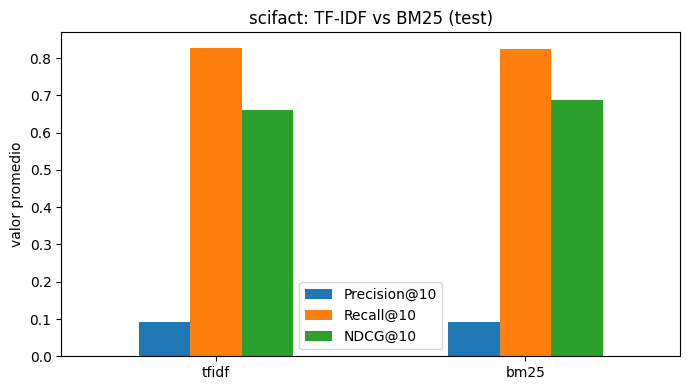

In [16]:
# Comparación por consulta (NDCG@10): victorias, empates y derrotas de BM25 frente a TF-IDF
diff = np.array([per_query["bm25"][q][2] - per_query["tfidf"][q][2] for q in test_qids])
print(f"BM25 > TF-IDF en {(diff>1e-9).sum()} consultas | empate en {(abs(diff)<=1e-9).sum()} | TF-IDF > BM25 en {(diff<-1e-9).sum()}")
print(f"Diferencia media de NDCG@10 (BM25 - TF-IDF): {diff.mean():+.4f}")
try:
    from scipy.stats import wilcoxon
    print("Wilcoxon pareado: p =", round(wilcoxon(diff).pvalue, 5))
except Exception as e:
    print("Prueba de Wilcoxon no disponible:", e)

import matplotlib.pyplot as plt
results.plot(kind="bar", figsize=(7, 4), rot=0, title=f"{CORPUS}: TF-IDF vs BM25 (test)")
plt.ylabel("valor promedio"); plt.tight_layout(); plt.show()

**Comentarios:** Se compara ambos modelos consulta por consulta (victorias/empates/derrotas, diferencia media y Wilcoxon) y grafica.

En el análisis consulta por consulta sobre NDCG@10, BM25 supera a TF-IDF en 60 consultas, empatan en 212 y pierde en 28 (más del doble de victorias para BM25). La prueba de Wilcoxon pareada arroja $p = 0.00186$ ($p < 0.01$), confirmando que la mejora media de +0.0271 es estadísticamente significativa y consistente a lo largo del corpus, no producto de valores atípicos.

## 5. Interpretación de resultados

1. **Superioridad estadísticamente significativa de BM25 (`NDCG@10`):**
   - **BM25** obtiene un NDCG@10 de `0.6873` frente al `0.6602` de **TF-IDF con coseno** (`+0.0271` o `+4.1%` relativo).
   - En las 300 consultas de `test`, BM25 gana en **60**, empata en **212** y pierde en **28** (relación > 2:1). La prueba de Wilcoxon pareada arroja **$p = 0.00186 < 0.01$**, confirmando que la mejora es consistente y estadísticamente significativa.

2. **Cobertura (`Recall@10`) y techo estructural (`Precision@10`):**
   - Ambos modelos recuperan más del **82%** de los documentos relevantes en el top-10 (**Recall@10** de `0.8277` en TF-IDF y `0.8245` en BM25) y empatan en **Precision@10 (`0.0910`)**.
   - El valor de `0.0910` no indica bajo rendimiento, sino una cota del dataset SciFact: con `339` pares relevantes en `300` consultas (`1.13` relevantes por consulta en promedio), el máximo teórico en un top-10 es `0.113` (alcanzando más del 80% del techo posible).

3. **Por qué BM25 supera a TF-IDF-coseno:**
   - Mientras la similitud coseno divide por la norma $L_2$ completa  de penalizando en exceso los abstracts largos, **BM25** aplica saturación de frecuencia ($k_1 = 1.5$) y normalización suave por longitud ($b = 0.75$ respecto a `avgdl = 138.7`), posicionando los documentos relevantes más cerca del rango 1.

4. **Limitaciones del sistema:**
   - Enfoque estrictamente léxico sin sinonimia ni semántica, casos puntuales de over-stemming con Porter (`does` → `doe`) o fragmentación numérica (`0-dimensional`), y uso de hiperparámetros estándar ($k_1, b$) sin ajuste previo.

## 6. Servicio web con FastAPI

El `app.py` carga `corpus.jsonl`, construye el índice al arrancar y expone `GET /health` y `POST /search` (validación: `model ∈ {bm25, tfidf}`, `top_k` entre 1 y 1000, consulta no vacía; respuestas ordenadas, sin duplicados y con ≤ `top_k` resultados).

In [17]:
%%writefile app.py
import os
from typing import Literal
from fastapi import FastAPI
from pydantic import BaseModel, Field

from ir_engine import SearchEngine, load_corpus_jsonl

CORPUS_PATH = os.environ.get("CORPUS_PATH", "corpus.jsonl")
CORPUS_NAME = os.environ.get("CORPUS_NAME", "scifact")

app = FastAPI(title="Servicio de recuperación de información")
engine = SearchEngine(load_corpus_jsonl(CORPUS_PATH))


class SearchRequest(BaseModel):
    query: str = Field(..., min_length=1)
    model: Literal["bm25", "tfidf"] = "bm25"
    top_k: int = Field(10, ge=1, le=1000)


@app.get("/health")
def health():
    return {"status": "ok", "corpus": CORPUS_NAME, "documents": engine.N}


@app.post("/search")
def search(req: SearchRequest):
    return {"model": req.model, "results": engine.search(req.query, req.model, req.top_k)}

Writing app.py


In [18]:
from pathlib import Path

Path("requirements.txt").write_text("fastapi\nuvicorn\nnumpy\nnltk\nscikit-learn\n")
Path("Dockerfile").write_text(f"""FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY ir_engine.py app.py corpus.jsonl ./
ENV CORPUS_NAME={CORPUS}
EXPOSE 7860
CMD ["sh", "-c", "uvicorn app:app --host 0.0.0.0 --port ${{PORT:-7860}}"]
""")
# README con metadatos requeridos por Hugging Face Spaces (Docker)
Path("README.md").write_text("---\ntitle: IR Search\nemoji: 🔎\ncolorFrom: blue\ncolorTo: green\nsdk: docker\napp_port: 7860\n---\n")
print("Archivos para desplegar: app.py, ir_engine.py, corpus.jsonl, requirements.txt, Dockerfile, README.md")

Archivos para desplegar: app.py, ir_engine.py, corpus.jsonl, requirements.txt, Dockerfile, README.md


In [19]:
# Prueba local del servicio (sin red)
from fastapi.testclient import TestClient
import importlib, app as app_module
importlib.reload(app_module)
client = TestClient(app_module.app)

print(client.get("/health").json())
for m in ("bm25", "tfidf"):
    r = client.post("/search", json={"query": "vitamin D and cancer risk", "model": m, "top_k": 5})
    print(m, r.status_code, [(x["rank"], x["document_id"], x["score"]) for x in r.json()["results"]])
print("model inválido ->", client.post("/search", json={"query": "x", "model": "foo"}).status_code)

{'status': 'ok', 'corpus': 'scifact', 'documents': 5183}
bm25 200 [(1, '12009265', 17.455648), (2, '38551172', 16.352461), (3, '12074066', 15.883888), (4, '12810152', 14.201617), (5, '30720103', 13.919215)]
tfidf 200 [(1, '12009265', 0.334549), (2, '30720103', 0.302601), (3, '22843838', 0.301956), (4, '38551172', 0.298475), (5, '12074066', 0.29269)]
model inválido -> 422


**Comentarios:** Primero creamos app.py exponiendo los endpoints GET /health y POST /search con validación de esquema mediante Pydantic (model restringido a bm25/tfidf y top_k entre 1 y 1000). Luego se generaron los 3 archivos de configuración para contenerizar el servicio en Python 3.11-slim y desplegarlo con SDK Docker en Hugging Face Spaces y con la prueba se puede observar que /health confirma el estado ok con 5,183 documentos indexados. Ambas búsquedas devuelven 200 OK con rankings descendentes, sin duplicados y con alta coincidencia en el top-5 (ambos modelos posicionan el documento 12009265 en el rango 1), mientras que un modelo inválido es rechazado correctamente con código 422.